### 📦 1 | Install & Import Required Packages
---

#### 1.1 | Install Required Packages
---

In [ ]:
!pip install biopython >/dev/null
!pip install plotnine >/dev/null

#### 1.2 | Import Required Packages
---

In [ ]:
from    Bio import Entrez
import  pandas as pd
from    datetime import datetime
import  matplotlib.pyplot as plt
from    plotnine import *
from    mizani.formatters import comma_format
import  time

### 🔧 2 | Parameters
---

#### 2.1 | Define Diseases to Plot
---

In [ ]:
# Create list of diseases for plotting | ['Long COVID', 'ME/CFS', 'Fibromyalgia', 'POTS', 'MCAS', 'Chronic Lyme', 'Dysautonomia', 'PANS/PANDAS', 'HIV/AIDS', 'Multiple Sclerosis', 'Parkinson\'s Disease', 'Rheumatoid Arthritis']
disease_list = ['Long COVID', 'ME/CFS', 'Fibromyalgia', 'POTS', 'MCAS', 'Chronic Lyme', 'Dysautonomia', 'PANS/PANDAS']

#### 2.2 | Define Plot Colours for Each Disease
---

In [ ]:
# Define disease colours
disease_colors = {
    "ME/CFS": "#7BB3F3",
    "Long COVID": "#E57399",
    "Fibromyalgia": "#FFD8A8",
    "POTS": "#B6FDFF",
    "MCAS": "#9FE0C3",
    "Chronic Lyme": "#B4D9B5",
    "Dysautonomia": "#B6C4F2",
    "PANS/PANDAS": "#F4B6A6",
    "HIV/AIDS": "#F2A9A1",
    "Multiple Sclerosis": "#D3D3D3",
    "Parkinson's Disease": "#D7B3FF",
    "Rheumatoid Arthritis": "#B4D9B5"
}

#### 2.3 | Define Time Period
---

In [ ]:
# Define the start and end years for the PubMed API search
start_year = 1980
end_year = 2025

# Define single year for across-disease comparison
single_year = 2024

#### 2.4 | Define Search Terms for PubMed Entrez API (MeSH and Title/Abstract Keywords)
---

In [ ]:
# Define a helper function to build the 'MeSH OR tiab' queries
def build_mesh_tiab_query(mesh_terms=None, tiab_phrases=None, extra_clauses=None):
    """
    Build a PubMed query that matches either:
      - MeSH Terms (major topic indexing), OR
      - Title/Abstract phrases ([tiab])
    Optionally add extra clauses (already field-tagged) like Supplementary Concept, etc.
    """
    mesh_terms = mesh_terms or []
    tiab_phrases = tiab_phrases or []
    extra_clauses = extra_clauses or []

    parts = []

    if mesh_terms:
        mesh_part = " OR ".join([f'"{t}"[MeSH Terms]' for t in mesh_terms])
        parts.append(f"({mesh_part})")

    if tiab_phrases:
        tiab_part = " OR ".join([f'"{p}"[tiab]' for p in tiab_phrases])
        parts.append(f"({tiab_part})")

    if extra_clauses:
        extra_part = " OR ".join(extra_clauses)
        parts.append(f"({extra_part})")

    # If nothing provided, return empty string (caller should handle)
    return "(" + " OR ".join(parts) + ")" if parts else ""

# Define the search terms
search_terms = {
    "ME/CFS": build_mesh_tiab_query(
        mesh_terms=["Myalgic Encephalomyelitis", "Chronic Fatigue Syndrome"],
        tiab_phrases=[
            "ME/CFS",
            "CFS/ME",
            "myalgic encephalomyelitis",
            "chronic fatigue syndrome",
            "systemic exertion intolerance disease",
            "SEID"
        ]
    ),

    "Long COVID": build_mesh_tiab_query(
        mesh_terms=["Post-Acute COVID-19 Syndrome"],  # if not present/too new, tiab still captures
        tiab_phrases=[
            "Long COVID",
            "post-COVID syndrome",
            "post-COVID-19 condition",
            "long-haul COVID",
            "post-acute sequelae of COVID-19",
            "PASC"
        ]
    ),

    "Fibromyalgia": build_mesh_tiab_query(
        mesh_terms=["Fibromyalgia"],
        tiab_phrases=["fibromyalgia", "fibromyalgia syndrome"]
    ),

    "POTS": build_mesh_tiab_query(
        mesh_terms=["Postural Orthostatic Tachycardia Syndrome"],
        tiab_phrases=[
            "postural orthostatic tachycardia syndrome",
            "postural tachycardia syndrome",
            "POTS",
            "PoTS"
        ]
    ),

    "MCAS": build_mesh_tiab_query(
        mesh_terms=["Mast Cell Activation Syndrome"],
        tiab_phrases=[
            "mast cell activation syndrome",
            "mast cell activation disorder",
            "MCAS",
            "MCAD"
        ]
    ),

    "Dysautonomia": build_mesh_tiab_query(
        mesh_terms=["Dysautonomia"],
        tiab_phrases=["dysautonomia"]
    ),

    "Chronic Lyme": build_mesh_tiab_query(
        mesh_terms=["Lyme Disease", "Post-Treatment Lyme Disease Syndrome"],
        tiab_phrases=[
            "chronic lyme",
            "chronic lyme disease",
            "post-treatment lyme disease syndrome",
            "PTLDS",
            "post-lyme disease syndrome",
            "neuroborreliosis"
        ]
    ),

    "PANS/PANDAS": build_mesh_tiab_query(
        mesh_terms=[
            "Pediatric Acute-Onset Neuropsychiatric Syndrome",
            "PANDAS"
        ],
        tiab_phrases=[
            "PANS",
            "pediatric acute-onset neuropsychiatric syndrome",
            "PANDAS",
            "pediatric autoimmune neuropsychiatric disorders associated with streptococcus"
        ]
    ),

    "Multiple Sclerosis": build_mesh_tiab_query(
        mesh_terms=["Multiple Sclerosis"],
        tiab_phrases=["multiple sclerosis"]
    ),

    "HIV/AIDS": build_mesh_tiab_query(
        mesh_terms=["HIV Infections", "Acquired Immunodeficiency Syndrome"],
        tiab_phrases=[
            "HIV",
            "AIDS",
            "HIV/AIDS",
            "human immunodeficiency virus"
        ]
    ),

    "Parkinson's Disease": build_mesh_tiab_query(
        mesh_terms=["Parkinson Disease"],
        tiab_phrases=[
            "parkinson disease",
            "parkinson's disease",
            "idiopathic parkinson's disease"
        ]
    ),

    "Rheumatoid Arthritis": build_mesh_tiab_query(
        mesh_terms=["Arthritis, Rheumatoid"],
        tiab_phrases=[
            "rheumatoid arthritis",
            "chronic polyarthritis"
        ]
    ),
}

### 🚰  3 | Data Import - from PubMed Entrez API
---

In [ ]:
def fetch_pubmed_data_for_multiple_terms(search_terms, start_year, end_year):
    Entrez.email = "your.email@example.org"  # Replace with a contact email before running

    publication_counts = {term: [] for term in search_terms}
    years = range(start_year, end_year + 1)

    for year in years:
        for disease_label, query in search_terms.items():
            full_query = f"{query} AND ({year}[dp])"

            handle = Entrez.esearch(
                db="pubmed",
                term=full_query,
                retmax=0  # we only need Count
            )
            record = Entrez.read(handle)
            count = int(record["Count"])
            publication_counts[disease_label].append(count)
            handle.close()

            time.sleep(0.34)

    df = pd.DataFrame(publication_counts, index=years)
    df.index.name = "Year"
    return df

# Fetching the data (to be executed in an environment where Biopython is installed)
publications_df = fetch_pubmed_data_for_multiple_terms(search_terms, start_year, end_year)

# Check result
publications_df.tail()

,ME/CFS,Long COVID,Fibromyalgia,POTS,MCAS,Dysautonomia,Chronic Lyme,PANS/PANDAS,Multiple Sclerosis,HIV/AIDS,Parkinson's Disease,Rheumatoid Arthritis
Year,,,,,,,,,,,,
2021,401,1012,888,458,172,280,447,183,6526,20749,9662,7212
2022,350,2403,888,440,149,245,411,168,6369,20195,9506,6920
2023,378,2863,962,454,166,262,360,183,5643,19068,9281,6667
2024,355,2909,971,434,133,283,399,230,5860,19647,9888,6715
2025,414,2545,1024,470,165,288,337,232,6064,20719,11107,7237


In [ ]:
# Transforming the DataFrame to long format
df_long = publications_df.reset_index().melt(id_vars='Year', var_name='Disease', value_name='Publications')

# Calculating cumulative publications for each disease
df_long['Cumulative Publications'] = df_long.groupby('Disease')['Publications'].cumsum()

# Check result
df_long.tail()

,Year,Disease,Publications,Cumulative Publications
547,2021,Rheumatoid Arthritis,7212,142894
548,2022,Rheumatoid Arthritis,6920,149814
549,2023,Rheumatoid Arthritis,6667,156481
550,2024,Rheumatoid Arthritis,6715,163196
551,2025,Rheumatoid Arthritis,7237,170433


### 🥋 4 | Data Wrangling
---

In [ ]:
# Filter dataframe for required diseases
df_plot_disease = df_long[df_long['Disease'].isin(disease_list)]

# Check result
df_plot_disease.tail(10)

,Year,Disease,Publications,Cumulative Publications
358,2016,PANS/PANDAS,90,1006
359,2017,PANS/PANDAS,125,1131
360,2018,PANS/PANDAS,128,1259
361,2019,PANS/PANDAS,113,1372
362,2020,PANS/PANDAS,136,1508
363,2021,PANS/PANDAS,183,1691
364,2022,PANS/PANDAS,168,1859
365,2023,PANS/PANDAS,183,2042
366,2024,PANS/PANDAS,230,2272
367,2025,PANS/PANDAS,232,2504


In [ ]:
# Filter for specific year selected
df_plot_disease_year = df_plot_disease[df_plot_disease['Year']==single_year]

# Sort values on Publications
df_plot_disease_year = df_plot_disease_year.sort_values('Publications', ascending=False)

# Changing 'Disease' to a categorical type with ordered categories
df_plot_disease_year['Disease'] = pd.Categorical(df_plot_disease_year['Disease'], categories=df_plot_disease_year['Disease'].unique())

# Check result
df_plot_disease_year.head(10)

,Year,Disease,Publications,Cumulative Publications
90,2024,Long COVID,2909,9467
136,2024,Fibromyalgia,971,16469
182,2024,POTS,434,6527
320,2024,Chronic Lyme,399,14044
44,2024,ME/CFS,355,7939
274,2024,Dysautonomia,283,3553
366,2024,PANS/PANDAS,230,2272
228,2024,MCAS,133,2619


### 📈  5 | Visualise Results
---

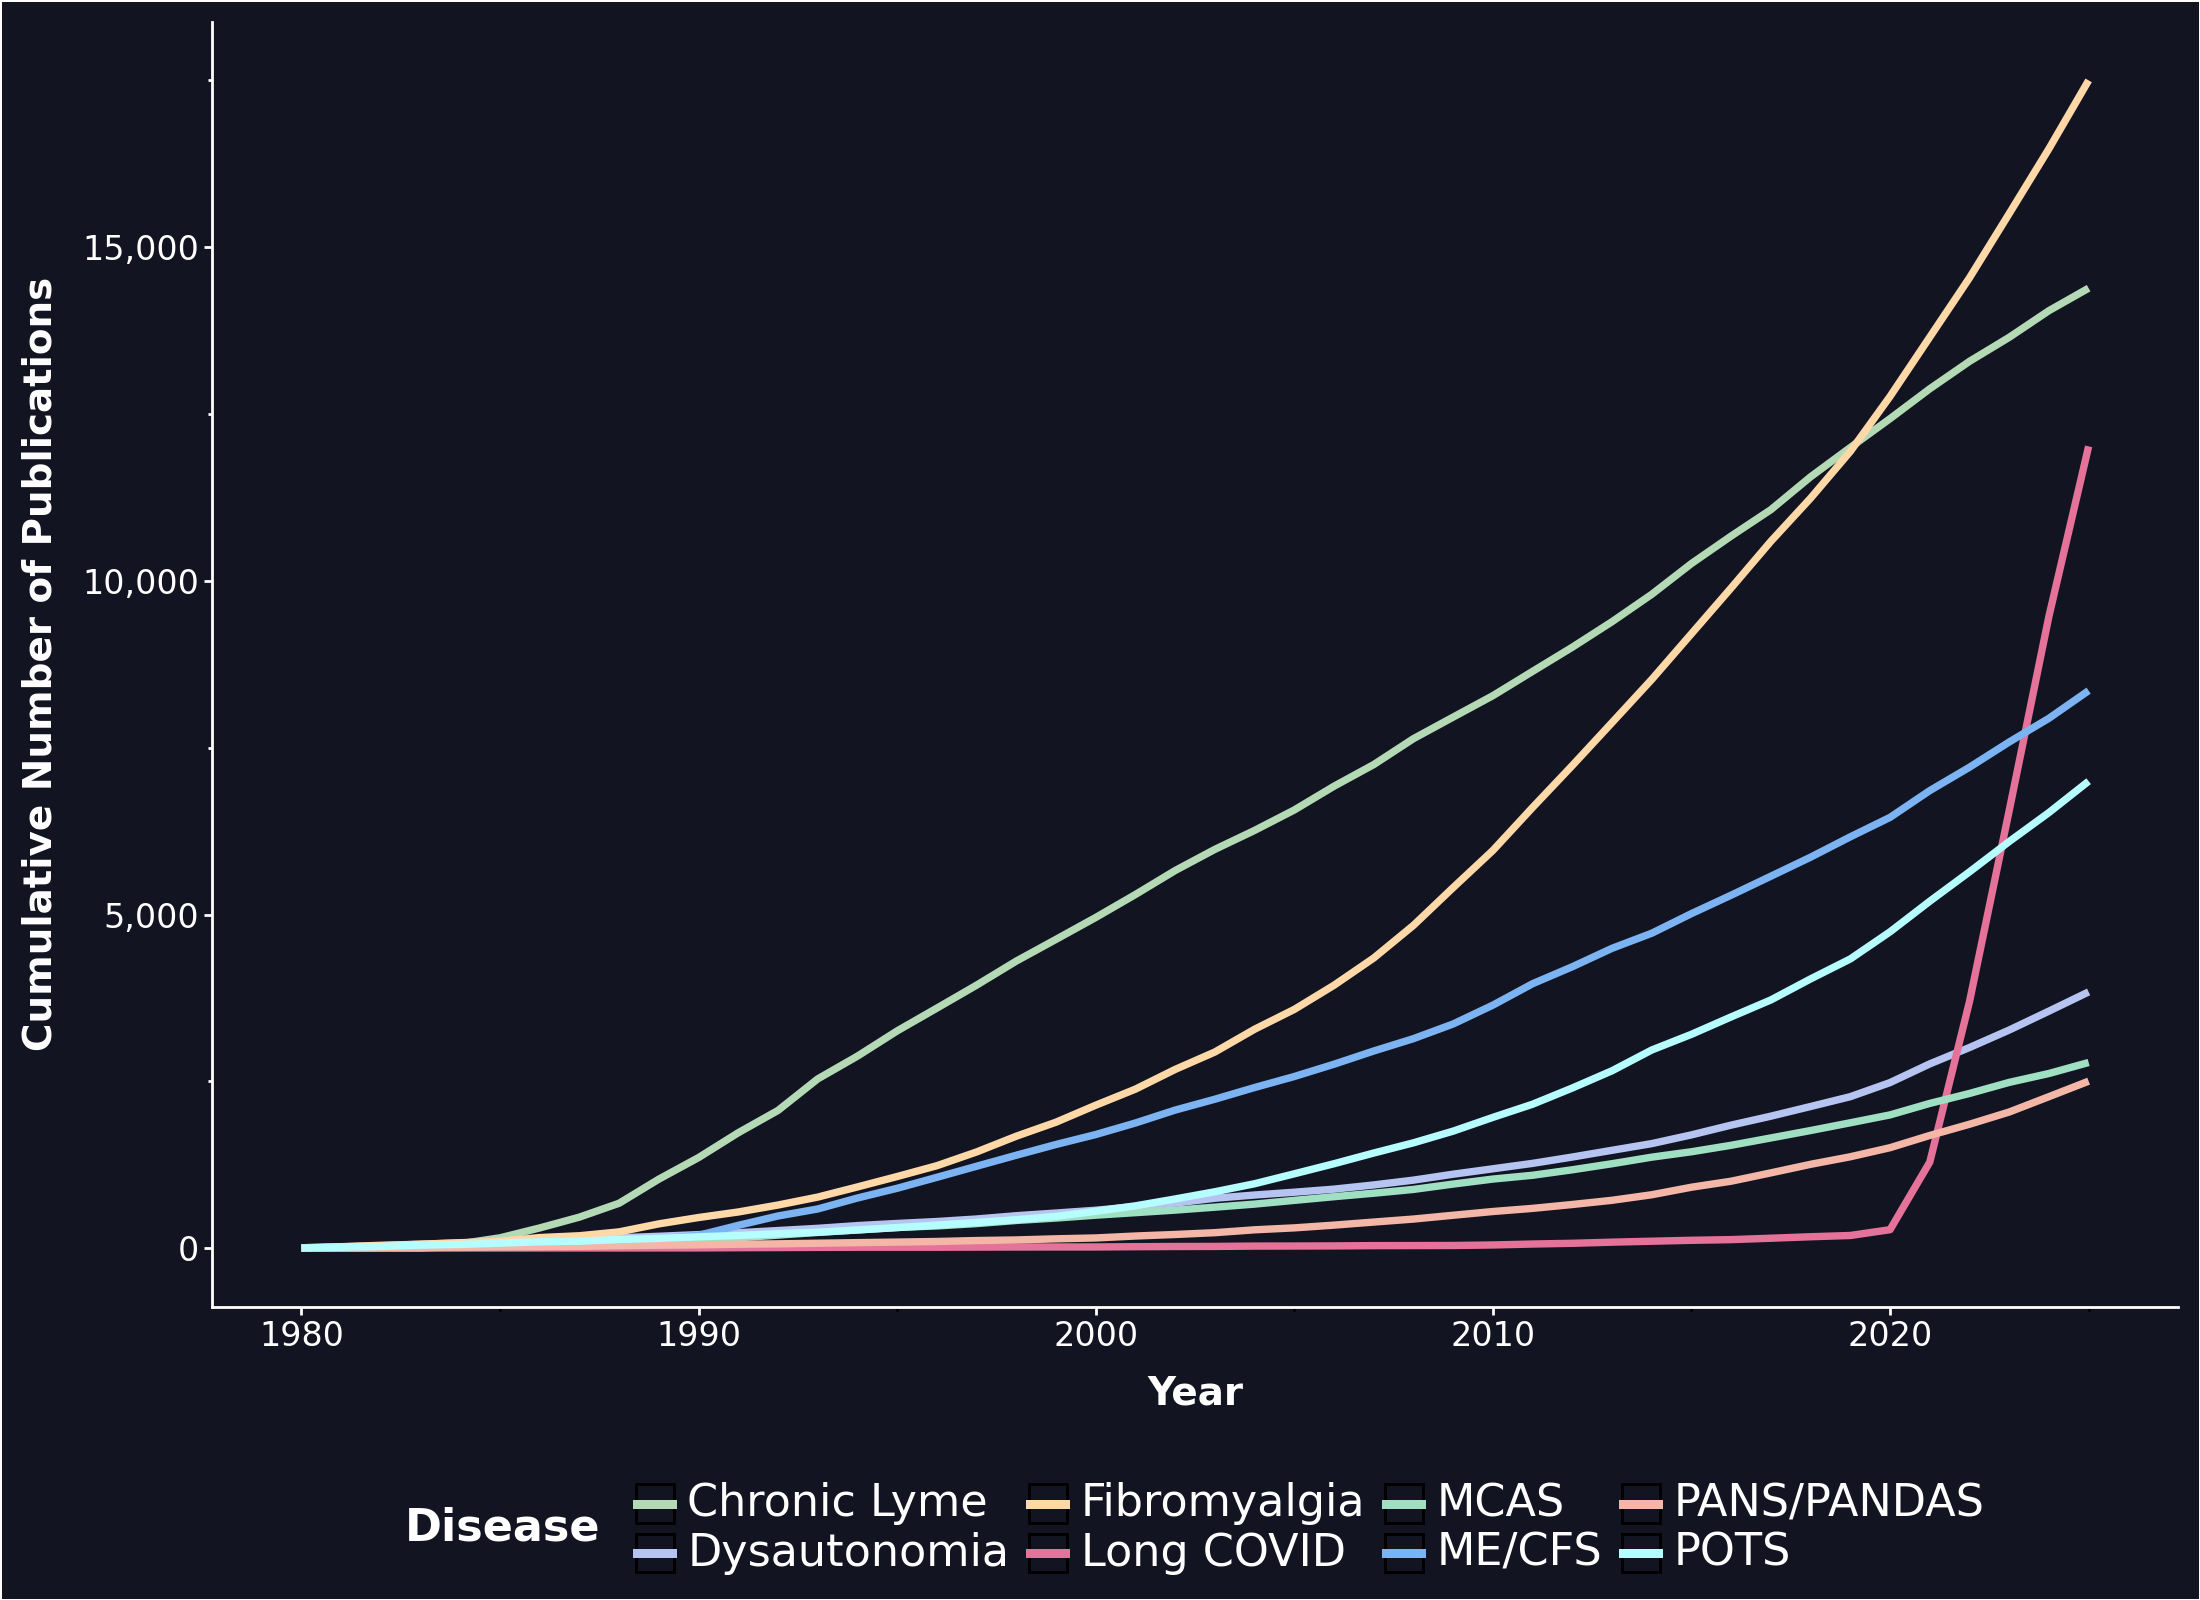

In [ ]:
# Update the cumulative plot with the new styling
cumulative_plot = (
    ggplot(df_plot_disease, aes(x='Year', y='Cumulative Publications', color='Disease')) +
    geom_line(size=1.5) +
    labs(
        x='Year',
        y='Cumulative Number of Publications'
    ) +
    theme_classic() +
    theme(
        # --- Figure ---
        figure_size=(11, 8),

        # --- Axes ---
        axis_title=element_text(size=14, weight='bold', color='white'),
        axis_text=element_text(size=12, color='white'),
        axis_line=element_line(color='white', size=1),
        axis_ticks=element_line(color='white', size=1),

        # --- Plot text ---
        plot_title=element_text(size=16, weight='bold', color='white', hjust=0),

        # --- Backgrounds ---
        plot_background=element_rect(fill='#121421', color=None),
        panel_background=element_rect(fill='#121421', color=None),

        # --- Legend ---
        legend_position='bottom',
        legend_box='horizontal',
        legend_title=element_text(size=16, weight='bold', color='white'),
        legend_text=element_text(size=16, color='white'),
        legend_background=element_rect(fill='#121421', color=None),
        legend_key=element_rect(fill='#121421', color=None),
    ) +
    scale_y_continuous(labels=comma_format()) +
    scale_color_manual(values=disease_colors)
)

# Display the plot
cumulative_plot